# 04 GB power price model

Hourly price `P = F + Y_month + S(time) + g(national wind) + X`, arithmetic
because GB prices go negative. F is the forward level (an input), the rest is
fitted. See `src/prs/price.py`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # make src/prs importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prs.plotting import fig, use_style, label_end, BLUE, ORANGE, AQUA, GREY
use_style()
pd.set_option("display.precision", 3)

Text(0.0, 1.0, 'Monthly mean Market Index price, 2017-2025')

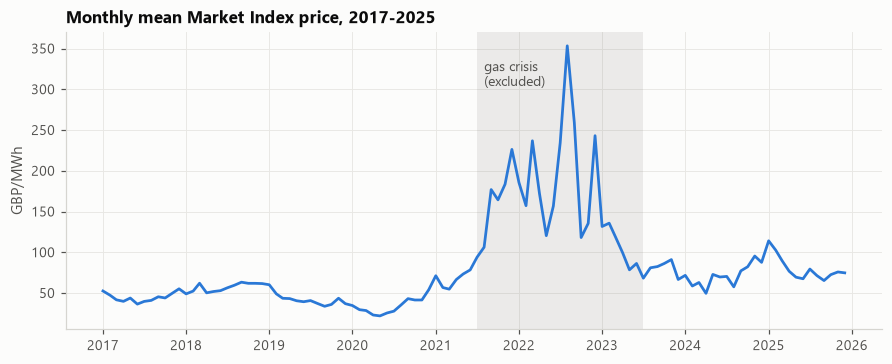

In [2]:
from prs.pipeline import load_models
from prs.price import design_matrix
m = load_models()
panel, price = m["panel"], m["price"]
monthly = panel["price"].resample("MS").mean()
f, ax = fig(figsize=(8, 3.2))
ax.plot(monthly.index, monthly.values, color=BLUE)
ax.axvspan(pd.Timestamp("2021-07-01", tz="UTC"), pd.Timestamp("2023-07-01", tz="UTC"), color=GREY, alpha=0.15, lw=0)
ax.text(pd.Timestamp("2021-08-01", tz="UTC"), monthly.max()*0.95, "gas crisis\n(excluded)", fontsize=9, color="#52514e", va="top")
ax.set_ylabel("GBP/MWh"); ax.set_title("Monthly mean Market Index price, 2017-2025")

The 2021-23 gas crisis dominates the history. Fitting a level to that
would make every future year look like 2022, so the level is set from an
assumed forward (default GBP 75/MWh, close to the post-crisis average) and
the crisis is used only for the gas-shock stress test.

## Daily shape

Text(0.0, 1.0, 'Fitted intraday price shape (post-crisis)')

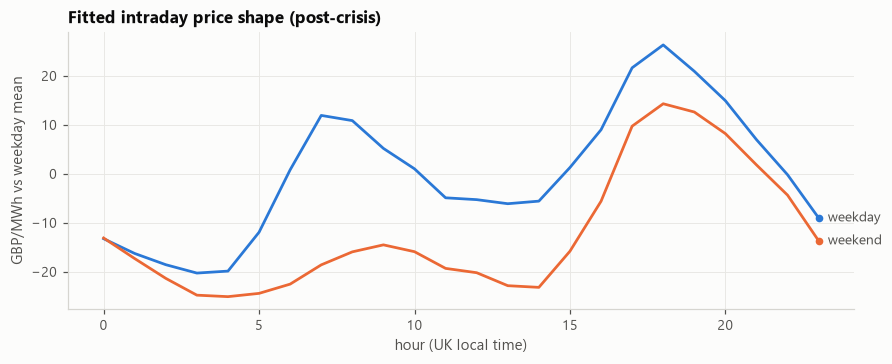

In [3]:
beta = price.beta
hours = np.arange(24)
wk = np.r_[0.0, beta[12:12+23]]          # weekday hours (hour 0 is the base)
we = beta[12+23:12+47]                    # weekend hours
f, ax = fig(figsize=(8, 3.2))
ax.plot(hours, wk - wk.mean(), color=BLUE); ax.plot(hours, we - wk.mean(), color=ORANGE)
label_end(ax, 23, wk[-1] - wk.mean(), "weekday", BLUE); label_end(ax, 23, we[-1] - wk.mean(), "weekend", ORANGE)
ax.set_xlabel("hour (UK local time)"); ax.set_ylabel("GBP/MWh vs weekday mean")
ax.set_title("Fitted intraday price shape (post-crisis)")

## Cannibalisation: price vs national wind

partial effect, season held fixed: GBP -77/MWh from CF 0 to 1
shape + wind regression R2: 0.41


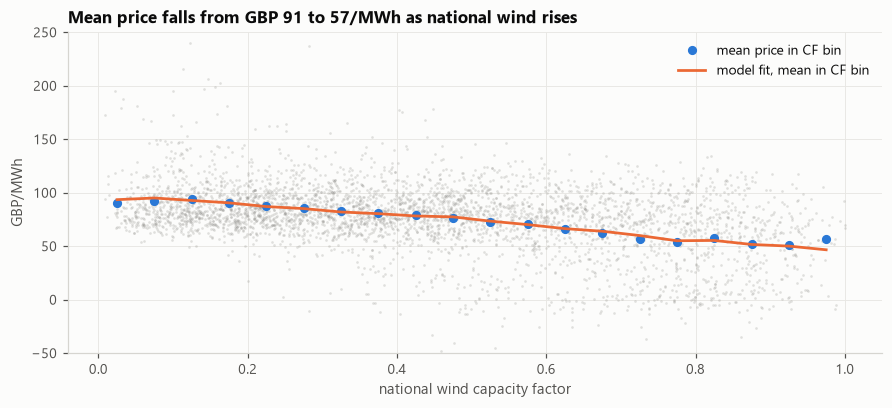

In [4]:
post = panel.loc["2023-07":"2025-12"].dropna(subset=["price", "national_cf"])
bins = pd.cut(post["national_cf"], np.linspace(0, 1, 21))
fitted = design_matrix(post.index, post["national_cf"].values) @ price.beta
binned = post.groupby(bins, observed=True)["price"].mean()
binned_fit = pd.Series(fitted, post.index).groupby(bins, observed=True).mean()
centres = [b.mid for b in binned.index]
b1, b2 = price.cannibal
f, ax = fig(figsize=(8, 3.6))
ax.scatter(post["national_cf"].sample(4000, random_state=0), post["price"].sample(4000, random_state=0),
           s=3, color=GREY, alpha=0.25, lw=0)
ax.plot(centres, binned.values, "o", ms=5, color=BLUE, label="mean price in CF bin")
ax.plot(centres, binned_fit.values, color=ORANGE, label="model fit, mean in CF bin")
ax.set_ylim(-50, 250); ax.set_xlabel("national wind capacity factor"); ax.set_ylabel("GBP/MWh")
ax.set_title(f"Mean price falls from GBP {binned.iloc[0]:.0f} to {binned.iloc[-1]:.0f}/MWh as national wind rises")
print(f"partial effect, season held fixed: GBP {b1+b2:.0f}/MWh from CF 0 to 1")
ax.legend(loc="upper right")
print(f"shape + wind regression R2: {price.info['shape_r2']:.2f}")

This is the heart of the project. When national wind is high, cheap wind
sets the price and prices collapse, sometimes below zero. Because Pen y
Cymoedd is windy at the same times, its average realised price (capture
price) is below the baseload average.

## Spikes and mean reversion

hourly AR(1) phi = 0.894  -> half-life 6.2 h
innovations: calm sd 7.8, spike sd 46.0, spike prob 3.5%
monthly level AR(1): phi = 0.82, sd = 7.3 GBP/MWh


,data,simulated
count,21953.0,525600.0
mean,76.3,77.1
std,35.7,36.8
min,-102.9,-167.0
1%,-10.6,-10.8
5%,8.3,17.8
50%,79.1,76.9
95%,119.7,137.1
99%,147.7,167.0
max,1297.4,315.5


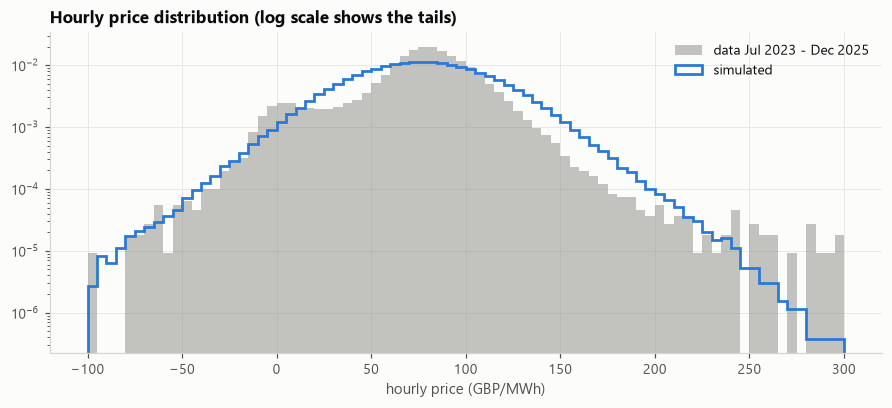

In [5]:
print(f"hourly AR(1) phi = {price.phi_hour:.3f}  -> half-life {np.log(0.5)/np.log(price.phi_hour):.1f} h")
print(f"innovations: calm sd {price.calm_sd:.1f}, spike sd {price.spike_sd:.1f}, spike prob {price.spike_w:.1%}")
print(f"monthly level AR(1): phi = {price.phi_month:.2f}, sd = {price.sigma_month:.1f} GBP/MWh")

idx = pd.date_range("2027-01-01", periods=8760 * 3, freq="h", tz="UTC")
_, cf_sim = m["wind"].simulate(idx, 20, seed=3)
p_sim = price.simulate(idx, cf_sim, forward=post["price"].mean(), seed=4)
f, ax = fig(figsize=(8, 3.6))
b = np.linspace(-100, 300, 81)
ax.hist(post["price"], bins=b, density=True, color=GREY, alpha=0.5, lw=0, label="data Jul 2023 - Dec 2025")
ax.hist(p_sim.ravel(), bins=b, density=True, histtype="step", color=BLUE, lw=1.8, label="simulated")
ax.set_yscale("log"); ax.set_xlabel("hourly price (GBP/MWh)")
ax.set_title("Hourly price distribution (log scale shows the tails)")
ax.legend()
pd.DataFrame({"data": post["price"].describe(percentiles=[.01, .05, .5, .95, .99]),
              "simulated": pd.Series(p_sim.ravel()).describe(percentiles=[.01, .05, .5, .95, .99])}).round(1)

The mean, the frequency of negative prices and the tails out to ~GBP 250/MWh
are reproduced, and spikes decay with a half-life of ~6 hours.

Limitations, stated honestly: the simulated body is a little too wide (the
real market clusters tightly around GBP 80), the real data has a small bump
near zero (hours when wind sets the price at its marginal cost) which a
smooth model does not create, and the very rare >GBP 300 scarcity spikes are
under-represented. For a monthly-settled revenue swap, the mean and the
wind-price link matter far more than single-hour extremes.